# B2B Satış Tahmini ve Stok Politikası Analizi
**ISL467E HW1 | 12 Kasım 2026**

Bu analiz, bir B2B dağıtıcısının 2020 yılı işlem verisi üzerinden haftalık satış tahminlerini,
ürünlerin ABC-XYZ sınıflandırmasını ve varsayımsal stok politikası eşiklerini inceler.
Hesaplamalar `analytics/` modüllerinde tanımlıdır; notebook ve Streamlit uygulaması aynı fonksiyonları kullanır.
Model karşılaştırmaları zaman sırasını korur. Tahminler ve stok eşikleri aşağıda belirtilen veri kapsamı ve varsayımlar için geçerlidir.

## 1. Kurulum ve tekrar üretilebilirlik
Önce proje klasöründe `python -m pip install -r requirements-notebook.txt` çalıştırın.
Terminalde `python -m jupyterlab` ile bu dosyayı açın. Paket kurma işlemi notebook çalıştırılırken
otomatik yapılmaz. Python 3.12 önerilir. Veri yolları proje köküne göre tanımlıdır.

In [1]:
from pathlib import Path
import sys, os, json, hashlib, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / 'data_loader.py').exists():
    raise FileNotFoundError('Notebook kernel çalışma klasörü, data_loader.py dosyasının bulunduğu proje klasörü olmalıdır.')
sys.path.insert(0, str(ROOT))
from data_loader import load_data
from analytics.forecasting import weekly_series, evaluate_models, future_forecast, metrics
from analytics.inventory import inventory_table

RESULTS = ROOT / 'results'
RESULTS.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (12, 4.6), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold',
                     'axes.grid': True, 'grid.alpha': .18, 'font.family': 'DejaVu Sans'})
COLORS = ['#2E5EAA', '#F28E2B', '#59A14F', '#E15759', '#76B7B2']
versions = pd.DataFrame({'Paket': ['pandas','numpy','scikit-learn','statsmodels','streamlit','matplotlib']})
versions['Sürüm'] = versions.Paket.map(importlib.metadata.version)
display(versions)

,Paket,Sürüm
0,pandas,3.0.1
1,numpy,2.3.5
2,scikit-learn,1.9.1
3,statsmodels,0.15.0
4,streamlit,1.67.0
5,matplotlib,3.11.2


## 2. Veri kapsamı ve ön işleme
Bir satır bir fatura ürün kalemidir. Fatura sayısı satır sayısından farklıdır.
`StockCode` ürün kimliğidir; başlığa göre farklı ürünler birleştirilmez.
`Revenue = Quantity × NetPrice` net cirodur; `UnitPrice` liste fiyatıdır.
Veri, ortak `data_loader.load_data()` fonksiyonu ile hazırlanır.

Ham dosyada 664.154 satır, 6.213 birebir tekrar, 6 eksik adet ve 5 sıfır adet vardır.
Negatif adet yoktur. Yükleyici tekrarları, geçersiz adetleri ve 0,01 TL altındaki fiyatları çıkarır;
eksik şehir/kategoriyi `Unknown` yapar. Temiz veri 657.855 satır içerir.
Satır kimliği bulunmadığından birebir tekrarların meşru iki ayrı kalem olup olmadığı kesin olarak belirlenemez.
İadeyi belirleyen ayrı bir alan bulunmamaktadır.

In [2]:
df = load_data()
required = {'InvoiceDate','StockCode','Description','Category','Quantity','Revenue','NetPrice'}
assert required.issubset(df.columns)
assert df[list(required)].isna().sum().sum() == 0
assert (df.Quantity > 0).all()
assert np.allclose(df.Revenue, df.Quantity * df.NetPrice)
assert not (df.Quantity % 1).any()
source_file = ROOT / 'data/B2B_Transaction_Data_.xlsx'
overview = pd.DataFrame({
    'Ölçü': ['Temiz satır','Ürün','Fatura','Müşteri','Toplam adet','Net ciro (TL)','İlk tarih','Son tarih'],
    'Değer': [f'{len(df):,}',f'{df.StockCode.nunique():,}',f'{df.InvoiceNo.nunique():,}',
              f'{df.CustomerID.nunique():,}',f'{df.Quantity.sum():,}',f'{df.Revenue.sum():,.2f}',
              str(df.InvoiceDate.min().date()),str(df.InvoiceDate.max().date())]})
display(overview)
print('Veri SHA256:', hashlib.sha256(source_file.read_bytes()).hexdigest())
display(pd.DataFrame({'Sütun':df.columns, 'Tür':df.dtypes.astype(str).values,
                      'Eksik':df.isna().sum().values}))

,Ölçü,Değer
0,Temiz satır,"657,855"
1,Ürün,"43,575"
2,Fatura,"47,467"
3,Müşteri,"1,201"
4,Toplam adet,"1,878,778"
5,Net ciro (TL),"29,417,403.34"
6,İlk tarih,2020-01-02
7,Son tarih,2020-12-31


Veri SHA256: 3f2ed80da1efa3a0714c8b9c77a2108732768a88b90a6f59fd6019eb523a327f


,Sütun,Tür,Eksik
0,InvoiceNo,string,0
1,CustomerID,string,0
2,InvoiceDate,datetime64[us],0
3,StockCode,str,0
4,Description,string,0
5,Category,string,0
6,City,string,0
7,Quantity,int64,0
8,NetPrice,float64,0
9,UnitPrice,float64,0


## 3. Neden haftalık tahmin?
Yalnızca 12 aylık veri vardır. Haftalık toplama 51 tam Pazartesi-Pazar gözlemi verir.
Kısmi ilk ve son haftalar model eğitiminden çıkarılır; gerçek toplam satış raporundan silinmez.
İç dönemde işlemi olmayan gün/haftalar sıfır **gözlenen satış** olarak tutulur. Bu, veri aktarımının
sürekli ve ürünün satışa açık olduğu varsayımıdır. Sıfır satışın stok yokluğu, kapanış veya eksik aktarım
olup olmadığını veri tek başına belirleyemez. Yıllık mevsimselliği doğrulamak için en az iki döngü yoktur.

,Değer
transaction_start,2020-01-02 00:00:00
transaction_end,2020-12-31 00:00:00
complete_start,2020-01-06 00:00:00
complete_end,2020-12-27 00:00:00
excluded_lines,24320
n_weeks,51
included_total,1828966.0
excluded_total,49812.0


,Başlangıç,Bitiş,İşlemsiz gün
Run,,,
14,2020-04-23,2020-04-26,4
20,2020-05-16,2020-05-19,4
22,2020-05-23,2020-05-26,4
42,2020-07-22,2020-08-02,12


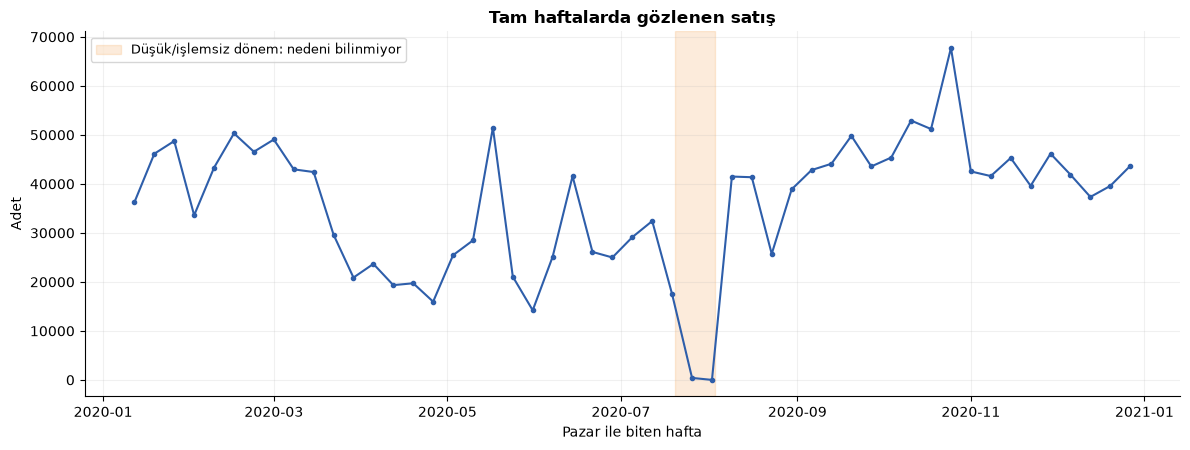

**İçgörü:** 51 tam haftada 1,828,966 adet satış var. Kısmi sınır haftalarında 49,812 adet eğitim dışında tutuldu. 26 Temmuz haftasında 404 adet, 2 Ağustos haftasında sıfır satış var. Bu dönemin veri aktarımı veya operasyon kesintisi olup olmadığı kontrol edilmelidir.

In [3]:
y, window = weekly_series(df, 'Quantity')
display(pd.DataFrame([window]).T.rename(columns={0:'Değer'}))
daily_rows = df.groupby('InvoiceDate').size().reindex(
    pd.date_range(df.InvoiceDate.min(), df.InvoiceDate.max(), freq='D'), fill_value=0)
gaps = daily_rows.eq(0)
gap_id = gaps.ne(gaps.shift()).cumsum()
gap_table = pd.DataFrame({'Date':daily_rows.index, 'Zero':gaps.values, 'Run':gap_id.values})
long_gaps = (gap_table[gap_table.Zero].groupby('Run').Date.agg(['min','max','size'])
             .rename(columns={'min':'Başlangıç','max':'Bitiş','size':'İşlemsiz gün'}))
display(long_gaps[long_gaps['İşlemsiz gün'] >= 4])
fig, ax = plt.subplots()
ax.plot(y.index, y, color=COLORS[0], marker='o', markersize=3)
ax.axvspan(pd.Timestamp('2020-07-20'), pd.Timestamp('2020-08-03'), color=COLORS[1], alpha=.17,
           label='Düşük/işlemsiz dönem: nedeni bilinmiyor')
ax.set(title='Tam haftalarda gözlenen satış', xlabel='Pazar ile biten hafta', ylabel='Adet')
ax.legend(loc='upper left', fontsize=9)
fig.tight_layout()
fig.savefig(RESULTS/'weekly_sales.png', dpi=150)
plt.show()
display(Markdown(f'**İçgörü:** {len(y)} tam haftada {y.sum():,.0f} adet satış var. '
    f'Kısmi sınır haftalarında {window["excluded_total"]:,.0f} adet eğitim dışında tutuldu. '
    '26 Temmuz haftasında 404 adet, 2 Ağustos haftasında sıfır satış var. '
    'Bu dönemin veri aktarımı veya operasyon kesintisi olup olmadığı kontrol edilmelidir.'))

## 4. Deney tasarımı ve aday modeller
**Model seçimi son test setini görmez.** İlk 43 hafta geliştirme, son 8 hafta testtir.
Geliştirme içinde artan eğitim pencereleri ile iki ayrı 8 haftalık doğrulama yapılır.
Seçim ölçütü önceden belirlenen **doğrulama RMSE**'sidir. Test sonuçları yalnızca seçilmiş
yöntemin dış örneklem performansını ve diğer adayların karşılaştırmasını raporlar.

| Model | Sabit ayar ve gerekçe |
|---|---|
| Naive | Son eğitim haftasını tüm ufka taşır; zorunlu basit kıyas noktası. |
| 4 haftalık ortalama | Son dört eğitim gözleminin ortalamasını taşır. |
| Holt damped | Holt-Winters ailesi, toplamsal sönümlenen trend; yıllık mevsimsellik devre dışı. |
| ARIMA | (1,1,1), drift; test üzerinde parametre araması yok. |
| Random Forest | 200 ağaç, derinlik 4, en az 2 yaprak gözlemi, random_state=42. |

RF girdileri 1/2/3/4/8/13 haftalık gecikmeler, geçmiş 4 haftalık ortalama/standart sapma,
geçmiş 13 haftalık ortalama ve zaman sırasıdır. Gelecek tahminlerde gecikmeler kendi tahminleriyle
ilerler; test gerçekleriyle güncellenmez. Negatif model çıktıları sıfıra kırpılır ve bu kural tüm
modellerin değerlendirmesine de uygulanır. Sabit parametreler küçük örneklemde aşırı aramayı sınırlar.

$$RMSE=\sqrt{\frac{1}{n}\sum(y_t-\hat y_t)^2},\quad
MAPE=\frac{100}{n_{y\ne0}}\sum_{y_t\ne0}\left|\frac{y_t-\hat y_t}{y_t}\right|,$$
$$WAPE=100\frac{\sum|y_t-\hat y_t|}{\sum|y_t|}.$$

MAPE sıfır gerçekleşmeleri dışlar, `MAPE_n` paydasını raporlar. Çok küçük pozitif satışlar MAPE'yi
şişirebilir; WAPE ve RMSE bu yüzden birlikte sunulur. Yakınsamayan bir model sessizce başka bir
yöntemle değiştirilmez; hata tablosunda gösterilir.

In [4]:
evaluation = evaluate_models(y)
split_rows = []
for origin in evaluation['origins']:
    split_rows.append({'Bölüm':'CV', 'Eğitim sonu':origin,
        'Doğrulama başlangıcı':origin+pd.Timedelta(weeks=1),
        'Doğrulama sonu':origin+pd.Timedelta(weeks=8)})
split_rows.append({'Bölüm':'Dokunulmamış test','Eğitim sonu':evaluation['development_end'],
                  'Doğrulama başlangıcı':evaluation['test_start'],'Doğrulama sonu':evaluation['test_end']})
display(pd.DataFrame(split_rows))
display(evaluation['cv'].round(3))
display(evaluation['test_scores'].round(3))
if not evaluation['issues'].empty:
    display(evaluation['issues'])
winner = evaluation['winner']
print('Doğrulama RMSE ile seçilen model:', winner)

,Bölüm,Eğitim sonu,Doğrulama başlangıcı,Doğrulama sonu
0,CV,2020-07-12,2020-07-19,2020-09-06
1,CV,2020-09-06,2020-09-13,2020-11-01
2,Dokunulmamış test,2020-11-01,2020-11-08,2020-12-27


,Model,RMSE,MAE,MAPE_pct,WAPE_pct,MAPE_n,n
0,Naive,14806.007,11013.625,547.820,29.111,15,16
1,Moving average (4),15977.920,13791.125,483.666,36.452,15,16
2,Holt damped,16858.621,14797.809,493.155,39.113,15,16
3,Random Forest,21348.405,19483.189,522.812,51.497,15,16
4,"ARIMA(1,1,1)",22902.633,21157.441,444.236,55.922,15,16


,Model,RMSE,MAE,MAPE_pct,WAPE_pct,MAPE_n,n
0,Naive,2907.909,2522.750,6.141,6.023,8,8
1,Moving average (4),12047.810,11709.750,28.546,27.956,8,8
2,Holt damped,10319.349,9888.511,24.193,23.608,8,8
3,"ARIMA(1,1,1)",3692.289,2832.501,6.470,6.762,8,8
4,Random Forest,10975.587,9901.785,24.278,23.640,8,8


Doğrulama RMSE ile seçilen model: Naive


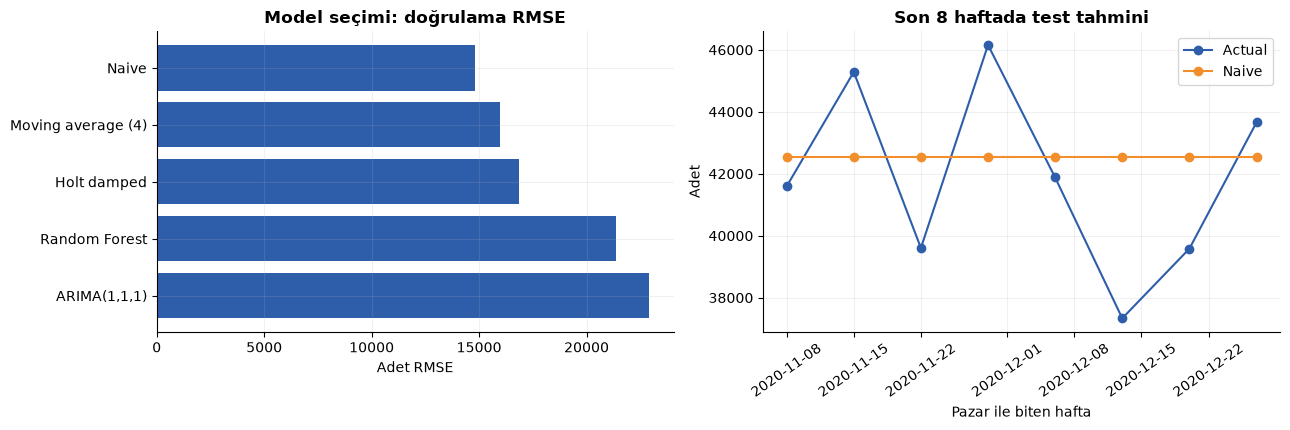

**İçgörü:** Naive, doğrulama RMSE ile seçildi. Doğrulama RMSE 14,806 adet, MAPE %547.8, WAPE %29.1. Son 8 haftada RMSE 2,908, MAPE %6.1. Doğrulama ile testin hata seviyeleri farklıdır; testin sakin dönemi başarıyı olduğundan genellenebilir gösterebilir. Daha karmaşık modeli yalnızca adından dolayı seçmek yerine, mevcut veride üstün gelen basit yöntemi kullanın.

In [5]:
fig, axes = plt.subplots(1,2,figsize=(13,4.4))
cv = evaluation['cv']
axes[0].barh(cv.Model[::-1], cv.RMSE[::-1], color=COLORS[0])
axes[0].set(title='Model seçimi: doğrulama RMSE', xlabel='Adet RMSE')
test = evaluation['test_predictions']
for name, color in [('Actual',COLORS[0]),(winner,COLORS[1])]:
    if name in test:
        axes[1].plot(test.index,test[name],label=name,color=color,marker='o')
axes[1].set(title='Son 8 haftada test tahmini',xlabel='Pazar ile biten hafta',ylabel='Adet')
axes[1].tick_params(axis='x',rotation=35)
axes[1].legend()
fig.tight_layout()
fig.savefig(RESULTS/'model_evaluation.png',dpi=150)
plt.show()
winner_test = evaluation['test_scores'].set_index('Model').loc[winner]
winner_cv = evaluation['cv'].set_index('Model').loc[winner]
display(Markdown(f'**İçgörü:** {winner}, doğrulama RMSE ile seçildi. Doğrulama RMSE '
    f'{winner_cv.RMSE:,.0f} adet, MAPE %{winner_cv.MAPE_pct:.1f}, WAPE %{winner_cv.WAPE_pct:.1f}. '
    f'Son 8 haftada RMSE {winner_test.RMSE:,.0f}, MAPE %{winner_test.MAPE_pct:.1f}. '
    'Doğrulama ile testin hata seviyeleri farklıdır; testin sakin dönemi başarıyı olduğundan genellenebilir gösterebilir. '
    'Daha karmaşık modeli yalnızca adından dolayı seçmek yerine, mevcut veride üstün gelen basit yöntemi kullanın.'))

## 5. 3/6/12 aylık ufuk ve belirsizlik
Arayüz seçenekleri yaklaşık 13/26/52 haftaya karşılık gelir. Seçilen yöntem tahmin üretirken tüm
tam haftalara yeniden uydurulur. Birinci tahmin haftası, son kısmi gerçek hafta ile örtüşebilir;
son eğitim haftası 27 Aralık, ilk tahmin haftası 3 Ocak ile biter. 28-31 Aralık gözlemleri modele verilmemiştir.

Yaklaşık %95 **tahmin aralığı** (ortalamanın güven aralığı değil) geliştirme içindeki doğrulama hatalarından hesaplanır:
$$q=Q_{0.95}(|e_h|/\sqrt{h}),\quad [\max(0,\hat y_h-q\sqrt h),\hat y_h+q\sqrt h].$$
Test verisi ne model seçiminde ne bu aralık kalibrasyonunda kullanılır. Yalnızca 16 bağımlı hata
bulunduğundan kapsama garantisi yoktur; ufukla karekök büyüme bir yaklaşımdır. 8 haftalık doğrulama,
52 haftalık tahminin başarısını kanıtlamaz. Uzun ufuklar keşif amaçlı planlama senaryosudur.

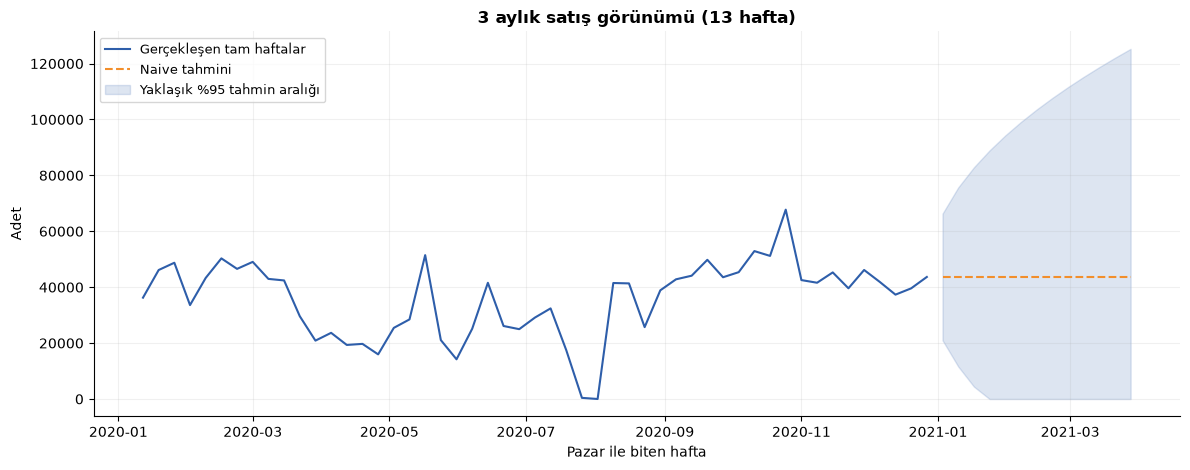

,Forecast,Lower95,Upper95
WeekEnd,,,
2021-01-03,43657.0,21020.4,66293.6
2021-01-10,43657.0,11644.0,75670.0
2021-01-17,43657.0,4449.2,82864.8
2021-01-24,43657.0,0.0,88930.2
2021-01-31,43657.0,0.0,94274.0
2021-02-07,43657.0,0.0,99105.1
2021-02-14,43657.0,0.0,103547.8
2021-02-21,43657.0,0.0,107683.0
2021-02-28,43657.0,0.0,111566.8


Dokunulmamış testte aralık kapsaması: %100.0


**İçgörü:** 13 haftalık nokta tahminlerinin toplamı 567,541 adet. Bantların tek tek toplamı, toplam talebin %95 aralığı olarak yorumlanamaz. Kısa vadede kapasite planlayın; uzun vadeli satın almayı yeni gerçekleşmelerle güncelleyin.

In [6]:
HORIZON_MONTHS = 3   # 3, 6 veya 12 olarak değiştirip hücreyi yeniden çalıştırın.
STEPS = {3:13, 6:26, 12:52}[HORIZON_MONTHS]
future = future_forecast(y, evaluation, STEPS)
fig, ax = plt.subplots(figsize=(12,4.8))
ax.plot(y.index,y,label='Gerçekleşen tam haftalar',color=COLORS[0])
ax.plot(future.index,future.Forecast,label=f'{winner} tahmini',color=COLORS[1],linestyle='--')
ax.fill_between(future.index, future.Lower95, future.Upper95, alpha=.16,
                color=COLORS[0],label='Yaklaşık %95 tahmin aralığı')
ax.set(title=f'{HORIZON_MONTHS} aylık satış görünümü ({STEPS} hafta)',xlabel='Pazar ile biten hafta',ylabel='Adet')
ax.legend(loc='upper left',fontsize=9)
fig.tight_layout()
fig.savefig(RESULTS/'forecast_units.png',dpi=150)
plt.show()
display(future.round(1))
print('Dokunulmamış testte aralık kapsaması:', f"%{evaluation['test_coverage']*100:.1f}")
display(Markdown(f'**İçgörü:** {len(future)} haftalık nokta tahminlerinin toplamı {future.Forecast.sum():,.0f} adet. '
    'Bantların tek tek toplamı, toplam talebin %95 aralığı olarak yorumlanamaz. '
    'Kısa vadede kapasite planlayın; uzun vadeli satın almayı yeni gerçekleşmelerle güncelleyin.'))

## 6. Ciro için bağımsız model karşılaştırması
Adet ve ciro ayrı hedeflerdir. Stok adedi ciro tahmininden türetilmez. Aşağıda aynı zaman ayrımı
net ciro için tekrarlanır; nominal TL tahmini fiyat/enflasyon değişimlerini ayrıca modellemez.

In [7]:
revenue_y, revenue_window = weekly_series(df, 'Revenue')
revenue_evaluation = evaluate_models(revenue_y)
display(revenue_evaluation['cv'].round(2))
display(revenue_evaluation['test_scores'].round(2))
rt = revenue_evaluation['test_scores'].set_index('Model').loc[revenue_evaluation['winner']]
display(Markdown(f'**İçgörü:** Net ciro için seçilen yöntem {revenue_evaluation["winner"]}. '
    f'Son 8 haftada RMSE {rt.RMSE:,.0f} TL ve MAPE %{rt.MAPE_pct:.1f}. '
    'Tahsilat veya kâr tahmini değildir; fiyat ve vade kararlarını ayrıca değerlendirin.'))

,Model,RMSE,MAE,MAPE_pct,WAPE_pct,MAPE_n,n
0,Naive,250196.72,173804.06,560.90,28.59,15,16
1,Moving average (4),271793.74,234973.20,460.44,38.65,15,16
2,Holt damped,362784.54,322560.26,492.40,53.06,15,16
3,Random Forest,363079.14,324707.42,508.95,53.41,15,16
4,"ARIMA(1,1,1)",368111.20,333663.72,441.59,54.88,15,16


,Model,RMSE,MAE,MAPE_pct,WAPE_pct,MAPE_n,n
0,Naive,55927.31,46703.19,6.86,6.76,8,8
1,Moving average (4),209291.74,201890.65,30.03,29.21,8,8
2,Holt damped,184526.36,174300.49,26.07,25.22,8,8
3,"ARIMA(1,1,1)",131704.51,113707.71,17.29,16.45,8,8
4,Random Forest,176852.30,153153.39,23.14,22.16,8,8


**İçgörü:** Net ciro için seçilen yöntem Naive. Son 8 haftada RMSE 55,927 TL ve MAPE %6.9. Tahsilat veya kâr tahmini değildir; fiyat ve vade kararlarını ayrıca değerlendirin.

## 7. Ürün bazlı ABC-XYZ
Varsayılan pencere son **90 takvim günü**dür. ABC bu penceredeki net ciroya göre, XYZ yalnızca
tam haftalardaki adet değişkenliğine göre hesaplanır. Ürün anahtarı `StockCode`'dur; aynı kodun
birden çok başlığı tek ürün olarak toplanır, gösterimde en son başlık kullanılır.

* **ABC:** ürün eklenmeden önceki birikimli ciro payı <%80 ise A, <%95 ise B, kalanı C.
  Eşiği geçen ürün önceki sınıfta kalır; böylece tek büyük ürün de A olabilir.
* **XYZ:** haftalık $CV=s/\bar d$. CV ≤0,5 X, 0,5<CV≤1 Y, CV>1 Z.
  Eşikler yorumlanabilir iş kurallarıdır; veriden öğrenilmiş evrensel sınırlar değildir.
* Talep olmayan iç haftalar sıfır olarak paydaya girer. Ortalama talep aralığı
  $ADI = \text{tam hafta sayısı}/\text{pozitif satışlı hafta sayısı}$.
  ADI≥1,32 kesikli talep uyarısı üretir. Bu uyarı bir tahmin modeli değildir.
* Ürün lansman tarihi ve stok mevcudu bilinmediğinden ortak pencerenin tamamında ürünün mevcut
  olduğu varsayılır. Kısa geçmişler ve kesikli talep manuel incelemeye işaretlenir.

,Varsayım / kapsam
start,2020-10-03 00:00:00
end,2020-12-31 00:00:00
days,90
complete_weeks,12
lead_days,14
lead_std_days,0.0
service_level,0.95
z,1.644854
x_limit,0.5
y_limit,1.0


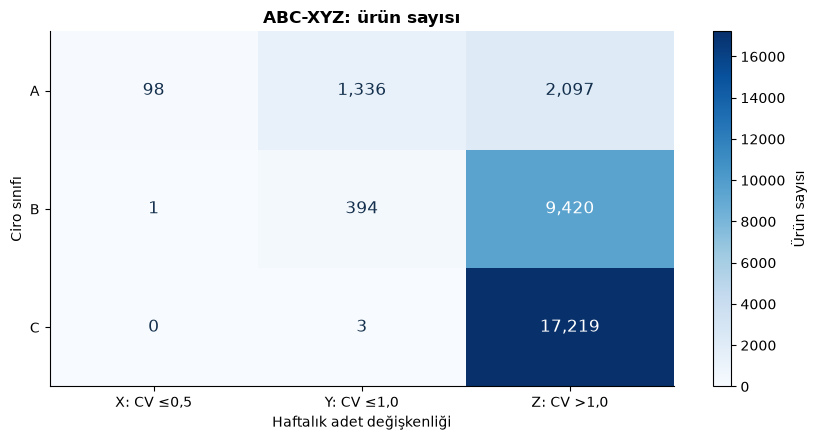

**İçgörü:** 32,581 üründen 3,531 A ürünü (%10.8) cironun %80.0 kısmını oluşturuyor. 2,097 AZ ürünü toplam cironun %31.4 kısmını sağlıyor. Bu ürünlerde tedarikçi teyidi ve sık gözden geçirme önceliklidir.

In [8]:
LOOKBACK_DAYS = 90
LEAD_DAYS = 14              # Kaynak veride yok: kullanıcı varsayımı
SERVICE_LEVEL = .95         # Çevrim hizmet olasılığı, doluluk oranı değil
LEAD_STD_DAYS = 0.          # Varsayılan: sabit teslim süresi
stock, policy_meta = inventory_table(df, LOOKBACK_DAYS, LEAD_DAYS, SERVICE_LEVEL, LEAD_STD_DAYS)
display(pd.DataFrame([policy_meta]).T.rename(columns={0:'Varsayım / kapsam'}))
matrix = (stock.groupby(['ABC','XYZ'],observed=True).size().unstack(fill_value=0)
          .reindex(index=['A','B','C'],columns=['X','Y','Z'],fill_value=0))
fig, ax = plt.subplots(figsize=(8.5,4.5))
im = ax.imshow(matrix.to_numpy(), cmap='Blues',aspect='auto')
for i in range(3):
    for j in range(3):
        value=matrix.iloc[i,j]
        ax.text(j,i,f'{value:,}',ha='center',va='center',
                color='white' if value>matrix.to_numpy().max()/2 else '#14304D',fontsize=12)
ax.set_xticks(range(3),['X: CV ≤0,5','Y: CV ≤1,0','Z: CV >1,0'])
ax.set_yticks(range(3),['A','B','C'])
ax.set(title='ABC-XYZ: ürün sayısı',xlabel='Haftalık adet değişkenliği',ylabel='Ciro sınıfı')
ax.grid(False)
fig.colorbar(im,ax=ax,label='Ürün sayısı')
fig.tight_layout()
fig.savefig(RESULTS/'abc_xyz.png',dpi=150)
plt.show()
aclass = stock[stock.ABC=='A']
az = stock[stock.ABC_XYZ=='AZ']
display(Markdown(f'**İçgörü:** {len(stock):,} üründen {len(aclass):,} A ürünü '
    f'(%{len(aclass)/len(stock)*100:.1f}) cironun %{aclass.RevenueShare.sum()*100:.1f} kısmını oluşturuyor. '
    f'{len(az):,} AZ ürünü toplam cironun %{az.RevenueShare.sum()*100:.1f} kısmını sağlıyor. '
    'Bu ürünlerde tedarikçi teyidi ve sık gözden geçirme önceliklidir.'))

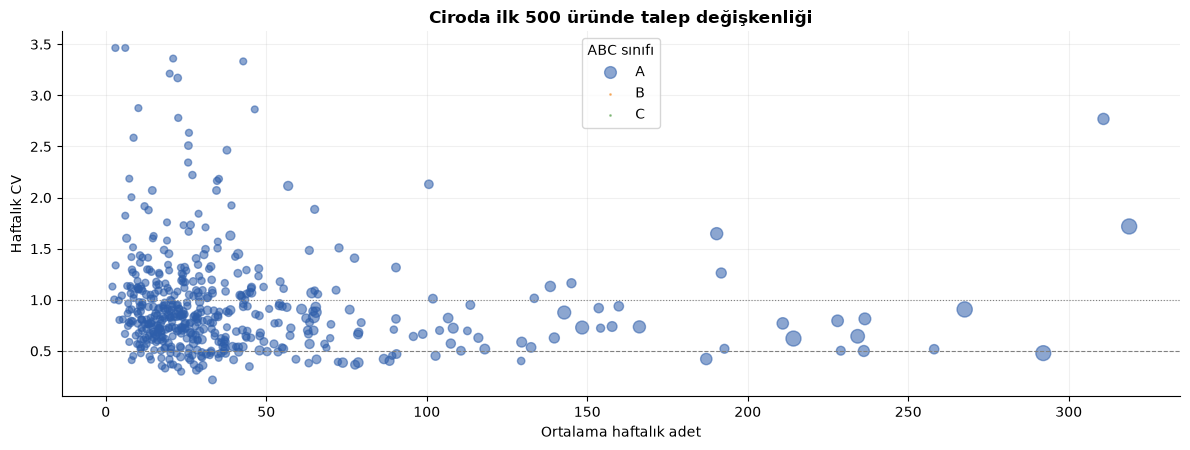

**İçgörü:** 28,738 üründe ADI≥1,32; 30,751 ürün kesikli talep veya kısa geçmiş nedeniyle manuel inceleme istiyor. CZ grubunda talebe bağlı tedarik ve küçük parti yaklaşımını değerlendirin; otomatik büyük stok hedefi uygulamayın.

In [9]:
top = stock.nlargest(500,'Revenue')
fig, ax = plt.subplots()
for cls,color in zip(['A','B','C'],COLORS):
    rows=top[top.ABC==cls]
    ax.scatter(rows.MeanWeekly,rows.CV,s=20+100*rows.Revenue/top.Revenue.max(),
               label=cls,color=color,alpha=.55)
ax.axhline(.5,color='grey',linestyle='--',linewidth=.8)
ax.axhline(1.,color='grey',linestyle=':',linewidth=.8)
ax.set(title='Ciroda ilk 500 üründe talep değişkenliği',xlabel='Ortalama haftalık adet',ylabel='Haftalık CV')
ax.legend(title='ABC sınıfı')
fig.tight_layout()
fig.savefig(RESULTS/'demand_variability.png',dpi=150)
plt.show()
display(Markdown(f'**İçgörü:** {stock.Intermittent.sum():,} üründe ADI≥1,32; '
    f'{stock.ManualReview.sum():,} ürün kesikli talep veya kısa geçmiş nedeniyle manuel inceleme istiyor. '
    'CZ grubunda talebe bağlı tedarik ve küçük parti yaklaşımını değerlendirin; otomatik büyük stok hedefi uygulamayın.'))

## 8. Güvenlik stoğu ve yeniden sipariş noktası
Veri setinde stok, açık sipariş, sipariş verilen tarih, vaat edilen ve gerçekleşen teslim tarihi yoktur.
**Gecikme performansı uydurulmaz.** Hesaplanan değer stok politikası eşiğidir; mevcut sipariş
miktarı değildir. Yeniden sipariş kararı envanter pozisyonu = eldeki + yoldaki − karşılanmamış
talep ile karşılaştırılmalıdır; bu veriyle o pozisyon hesaplanamaz.

Takvim günlerindeki ortalama ve örnek standart sapma sıfır satışlı günler dahil hesaplanır.
Bağımsız, durağan günlük talep ve teslim süresi varsayımıyla:
$$SS=z\sqrt{L\sigma_d^2+\mu_d^2\sigma_L^2},\quad ROP=\lceil L\mu_d+SS\rceil.$$
Sabit teslim süresinde $\sigma_L=0$ ve $SS=z\sigma_d\sqrt L$.
%95 çevrim hizmet düzeyi için $z\approx1,645$. SS görüntülemede yukarı yuvarlanır;
ROP, yuvarlanmamış SS ile hesaplandıktan sonra yukarı yuvarlanır.
Kesikli veya az gözlenen ürünlerde normal yaklaşımın güvenilirliği düşüktür. Promosyon,
stok yokluğu ve korelasyon etkileri gözlenmez; manuel inceleme alanı bu yüzden önemlidir.

In [10]:
cols=['StockCode','Description','ABC_XYZ','Revenue','MeanDaily','StdDaily','CV','ADI',
      'SafetyStockUnits','ReorderPoint','ManualReview','Policy']
display(stock[cols].head(15).round(3))
example = stock.iloc[0]
display(Markdown(f'**Örnek:** {example.StockCode} için günde ortalama {example.MeanDaily:,.2f} adet, '
    f'standart sapma {example.StdDaily:,.2f}. Varsayılan {LEAD_DAYS} gün teslim süresinde '
    f'güvenlik stoğu {example.SafetyStockUnits:,.0f}, yeniden sipariş noktası {example.ReorderPoint:,.0f} adet. '
    'Bu eşik sipariş vermek için stok pozisyonuyla birlikte kullanılmalıdır.'))

,StockCode,Description,ABC_XYZ,Revenue,MeanDaily,StdDaily,CV,ADI,SafetyStockUnits,ReorderPoint,ManualReview,Policy
0,9786058213241,Otuz Milyon Kelime - Çocuğunuzun Beynini Geliş...,AY,88976.358,36.478,112.292,0.906,1.000,692,1202,False,Frequent review; adjust buffers to demand vari...
1,9786257124492,Kral Şakir 9 - Muhtişim Dedektifler,AZ,87156.000,44.578,103.158,1.718,1.714,635,1259,True,High-value volatile demand; confirm orders bef...
2,9789751409935,Madalyonun İçi,AY,86351.463,29.500,56.652,0.621,1.000,349,762,False,Frequent review; adjust buffers to demand vari...
3,9786058422841,Dedemin Bakkalı,AX,84643.480,41.222,63.439,0.479,1.000,391,968,False,Frequent review; protect high-value stable sales.
4,9786056883569,Abartma Tozu,AY,67647.220,33.078,44.807,0.643,1.091,276,739,False,Frequent review; adjust buffers to demand vari...
5,9789751414601,Hayata Dön,AY,59660.743,19.500,36.093,0.876,1.000,223,496,False,Frequent review; adjust buffers to demand vari...
6,9789751416575,Kral Kaybederse,AY,59339.709,20.244,35.528,0.729,1.000,219,503,False,Frequent review; adjust buffers to demand vari...
7,9789751412874,Günahın Üç Rengi,AY,50202.693,22.467,32.850,0.735,1.000,203,517,False,Frequent review; adjust buffers to demand vari...
8,9786057611918,Karantina - Beşinci Perde-Ciltsiz,AZ,49916.300,26.378,81.367,1.647,2.400,501,871,True,High-value volatile demand; confirm orders bef...
9,9786059952767,Kraliçeyi Kurtarmak,AY,46138.820,31.622,84.294,0.814,1.000,519,962,False,Frequent review; adjust buffers to demand vari...


**Örnek:** 9786058213241 için günde ortalama 36.48 adet, standart sapma 112.29. Varsayılan 14 gün teslim süresinde güvenlik stoğu 692, yeniden sipariş noktası 1,202 adet. Bu eşik sipariş vermek için stok pozisyonuyla birlikte kullanılmalıdır.

## 9. Varsayımlara duyarlılık
Aynı ürünün stok eşiğinin farklı teslim süresi/hizmet düzeylerinde nasıl değiştiğini gösterir.
Bu tablo gözlenen tedarikçi performansı değildir. Her kombinasyon aynı geçmiş talep istatistiğini kullanır.

In [11]:
from statistics import NormalDist
sensitivity=[]
for lead in [7,14,28]:
    for service in [.90,.95,.99]:
        ss=NormalDist().inv_cdf(service)*example.StdDaily*np.sqrt(lead)
        sensitivity.append({'Teslim süresi (gün)':lead,'Hizmet düzeyi':service,
                            'Güvenlik stoğu':int(np.ceil(ss)),
                            'Yeniden sipariş noktası':int(np.ceil(example.MeanDaily*lead+ss))})
display(pd.DataFrame(sensitivity))
display(Markdown('**İçgörü:** Teslim süresi ve hizmet hedefi büyüdükçe stok eşiği artar. '
    'Stok yatırımı yapmadan önce varsayılan teslim süresini tedarikçiyle doğrulayın.'))

,Teslim süresi (gün),Hizmet düzeyi,Güvenlik stoğu,Yeniden sipariş noktası
0,7,0.90,381,637
1,7,0.95,489,745
2,7,0.99,692,947
3,14,0.90,539,1050
4,14,0.95,692,1202
5,14,0.99,978,1489
6,28,0.90,762,1783
7,28,0.95,978,1999
8,28,0.99,1383,2404


**İçgörü:** Teslim süresi ve hizmet hedefi büyüdükçe stok eşiği artar. Stok yatırımı yapmadan önce varsayılan teslim süresini tedarikçiyle doğrulayın.

## 10. Sonuç dosyaları ve kalite kontrolü
Tahmin, karşılaştırma ve stok tabloları CSV olarak kaydedilir. `StockCode` sütununu Excel'e alırken
metin türünü seçin; barkod bir sayı ölçüsü değildir. Dashboard'da aynı tablolar indirilebilir.
Testler, ayrılmış test verisinin değiştirilmesinin model seçimini/aralık kalibrasyonunu etkilemediğini,
sıfır günlerin stok varyansına katıldığını, tek ürünün A olabildiğini ve kısa geçmiş uyarılarını doğrular.

In [12]:
for target, series, ev in [('Quantity',y,evaluation),('Revenue',revenue_y,revenue_evaluation)]:
    series.to_csv(RESULTS/f'weekly_{target}.csv')
    ev['cv'].to_csv(RESULTS/f'cv_{target}.csv',index=False)
    ev['test_scores'].to_csv(RESULTS/f'test_{target}.csv',index=False)
    ev['cv_predictions'].to_csv(RESULTS/f'cv_predictions_{target}.csv',index=False)
    ev['test_predictions'].to_csv(RESULTS/f'test_predictions_{target}.csv')
    for months, steps in {3:13,6:26,12:52}.items():
        future_forecast(series,ev,steps).to_csv(RESULTS/f'forecast_{target}_{months}m.csv')
stock.to_csv(RESULTS/'abc_xyz_stock_policy.csv',index=False,encoding='utf-8-sig')
assert stock.StockCode.is_unique
assert np.isclose(stock.RevenueShare.sum(),1.)
assert stock.loc[~stock.ReorderPoint.isna(),'ReorderPoint'].ge(0).all()
assert y.index.max() < future.index.min()
assert all(origin < evaluation['test_start'] for origin in evaluation['origins'])
print('Tutarlılık kontrolleri geçti. Sonuçlar results/ klasörüne yazıldı.')

Tutarlılık kontrolleri geçti. Sonuçlar results/ klasörüne yazıldı.


## 11. Uygulama ve tekrar üretilebilirlik
Streamlit arayüzü `pages/forecast_supply.py` içindeki `render(df)` fonksiyonuyla oluşturulur.
Ana uygulama temizleme ve ortak filtreleme sonrasında aynı DataFrame'i ilgili sayfaya aktarır.
Model değerlendirmesi ve tahminler `@st.cache_data` ile önbelleklenir.
Yetersiz tarih kapsamı için açıklayıcı uyarı gösterilir; stok sekmesi kullanılabilir veriyi değerlendirir.

Uygulama proje kökünde `python -m streamlit run streamlit_app.py` komutuyla çalıştırılır.
Notebook tüm hücreleri sırayla çalıştırılarak tekrar üretilebilir. CSV ve grafik çıktıları
otomatik oluşturulan `results/` klasörüne yazılır. Analitik testler `tests/` klasöründedir.

## 12. Bulgular ve sınırlılıklar
1. **Zaman sızıntısı yok:** model seçimi geliştirme içi doğrulamada; son 8 hafta bağımsız denetimdir.
2. **Basit model kazanabilir:** mevcut veri üzerinde Naive üstün geldi. Bu sonuç gelişmiş modellerin denenmediği anlamına gelmez.
3. **Hata ölçüsü seçimi önemlidir:** sıfır/çok düşük haftalar nedeniyle MAPE tek başına uygun bir seçim ölçütü değildir.
4. **Satış ve gerçek talep aynı şey olmayabilir:** stok yokluğu ve veri kesintileri bilinmiyor.
5. **Stok önerisi varsayımlıdır:** teslim süresi ve hizmet hedefi kullanıcı girişidir; gerçekleşen gecikme verisi yoktur.
6. **Uzun ufuk sınırı:** bir yıllık geçmişle 12 aylık tahminin doğruluğu test edilmemiştir; yeni veriyle tekrar değerlendirme gerekir.

## Kaynaklar
* Veri ve ödev yönergesi: `ISL467E_HW1_2026.pdf` ve `B2B_Transaction_Data_.xlsx`.
* [Proje deposu](https://github.com/mertaliotay-maker/b2b-dashboard), commit `7f283baf029220b621051ba3ababea5cd48d4793`.
* [statsmodels ExponentialSmoothing](https://www.statsmodels.org/stable/generated/statsmodels.tsa.holtwinters.ExponentialSmoothing.html).
* [statsmodels ARIMA](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html).
* [scikit-learn RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html).
* [Hyndman ve Athanasopoulos, Forecasting: Principles and Practice, model değerlendirmesi](https://otexts.com/fpp3/toolbox.html).